In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [24]:
torch.manual_seed(42)

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [26]:

X_test = pd.read_csv('./DATASET/team10/task3/testing_data_set_10_data.csv', header=None)
y_test = pd.read_csv('./DATASET/team10/task3/testing_data_set_10_labels.csv', header=None)
X_train_L = pd.read_csv('./DATASET/team10/task3/training_data_set_10_labeled_data.csv', header=None)
y_train_L = pd.read_csv('./DATASET/team10/task3/training_data_set_10_labeled_labels.csv', header=None)
X_train_UL = pd.read_csv('./DATASET/team10/task3/training_data_set_10_unlabeled.csv', header=None)
X_val = pd.read_csv('./DATASET/team10/task3/validation_data_set_10_data.csv', header=None)
y_val = pd.read_csv('./DATASET/team10/task3/validation_data_set_10_labels.csv', header=None)

In [27]:
y_train_L

,0
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
745,4.0
746,4.0
747,4.0
748,4.0


In [28]:

scaler = StandardScaler()

scaler.fit(X_train_UL)
X_train_UL = scaler.transform(X_train_UL)
X_train_L = scaler.transform(X_train_L)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [29]:
X_test.shape, X_train_L.shape, X_train_UL.shape, X_val.shape, y_test.shape, y_train_L.shape, y_val.shape

((250, 36), (750, 36), (1750, 36), (250, 36), (250, 1), (750, 1), (250, 1))

In [30]:
class CustomDataset(Dataset):
    def __init__(self, features, labels=None, is_autoencoder=False):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.is_autoencoder = is_autoencoder

        if labels is not None:
            if is_autoencoder:
                self.labels = torch.tensor(labels, dtype=torch.float32)
            else:
                self.labels = torch.tensor(labels, dtype=torch.long)
        else:
            self.labels= None

    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        if self.labels is not None:
            return self.features[idx], self.labels[idx]
        return self.features[idx]

In [31]:
print("X_train_L shape:", X_train_L.shape)
print("y_train_L shape:", y_train_L.shape)
print("X_train_UL shape:", X_train_UL.shape)

X_train_L shape: (750, 36)
y_train_L shape: (750, 1)
X_train_UL shape: (1750, 36)


In [32]:
train_dataset_L = CustomDataset(X_train_L, y_train_L.squeeze())
train_dataset_UL = CustomDataset(X_train_UL, X_train_UL, is_autoencoder=True)
test_dataset = CustomDataset(X_test, y_test.squeeze())
val_dataset = CustomDataset(X_val, y_val.squeeze())

In [33]:
train_L_loader= DataLoader(train_dataset_L, batch_size=32, shuffle=True, pin_memory=True)
train_loader_UL = DataLoader(train_dataset_UL, batch_size=32, shuffle=True, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [34]:
val_dataset_UL = CustomDataset(X_val, X_val, is_autoencoder=True)
val_loader_UL = DataLoader(val_dataset_UL, batch_size=32, shuffle=False, pin_memory=True)

In [35]:
class AutoEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, bottleneck):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, bottleneck),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )
    
    def forward(self, x):
        encode = self.encoder(x)
        decode = self.decoder(encode)
        return decode
    def encode(self, x):
        return self.encoder(x)
    

In [36]:
class DFFNN(nn.Module):
    def __init__(self, i, h1, b1, h2, b2, h3, b3, op, pretrained=None):
        super().__init__()
        self.encoder_1 = nn.Sequential(
            nn.Linear(i, h1),
            nn.Tanh(),
            nn.Linear(h1, b1),
        )
        self.encoder_2 = nn.Sequential(
            nn.Linear(b1, h2),
            nn.Tanh(),
            nn.Linear(h2, b2),
        )
        self.encoder_3 = nn.Sequential(
            nn.Linear(b2, h3),
            nn.Tanh(),
            nn.Linear(h3, b3),
        )
        self.classifier = nn.Linear(b3, op)
        
        if pretrained is not None:
            ae_1, ae_2, ae_3 = pretrained
            self.encoder_1.load_state_dict(ae_1.encoder.state_dict())
            self.encoder_2.load_state_dict(ae_2.encoder.state_dict())
            self.encoder_3.load_state_dict(ae_3.encoder.state_dict())    
        
    def forward(self, x):
        x = self.encoder_1(x)
        x = self.encoder_2(x)
        x = self.encoder_3(x)
        return self.classifier(x)
        

In [37]:
import optuna
# BUG 1 FIXED: fixed_bot must default to None, not False! 
def find_best_aann_dimension(input_dim, train_loader, val_loader, l3_target, fixed_bot=None):
    def objective(trial):
        # h = trial.suggest_int("h", input_dim + 1, input_dim + 20)
        
        if fixed_bot is None:
            lb = l3_target + 1
            ub = max(lb, input_dim - 1)
            if lb >= ub:
                b = lb
            else:
                b = trial.suggest_int("b", lb, ub)
        else:
            b = fixed_bot
        
        h_lb = min(b+1, input_dim - 1)
        h = trial.suggest_int("h", h_lb , input_dim - 1)
        model = AutoEncoder(input_dim, h, b).to(device)
        optimizer= optim.Adam(model.parameters(), lr = 1e-3)
        criterion = nn.MSELoss()
        
        model.train()
        for epoch in range(25):
            # BUG 2 FIXED: Typo was "X_bech"
            for X_batch, _ in train_loader:
                X_batch = X_batch.to(device)
                optimizer.zero_grad()
                loss = criterion(model(X_batch), X_batch)
                loss.backward()
                optimizer.step()
        
        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for X_val_batch, _ in val_loader:
                X_val_batch = X_val_batch.to(device)
                # BUG 3 FIXED: Added .item() * size(0) to prevent memory leak
                v_loss = criterion(model(X_val_batch), X_val_batch)
                total_val_loss += v_loss.item() * X_val_batch.size(0)
                
        return total_val_loss / len(val_loader.dataset)
    
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=10)
    
    return study.best_params

In [38]:
import copy

def train_DFFNN(model, train_loader, val_loader, lr=1e-3, threshold=1e-5):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    epoch = 0
    avg_train_loss_list = []
    avg_val_loss_list = []
    
    prev_train_loss = float('inf')
    best_val_loss = float('inf')
    best_model_weights = None
    
    print(f"--------------------- DFFNN model training ---------------------")
    
    while epoch < 10000:
        # 1. TRAINING
        model.train()
        total_train_loss = 0.0
        for batch_features, batch_labels in train_loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * batch_features.size(0)
            
        avg_train_loss = total_train_loss / len(train_loader.dataset)
        avg_train_loss_list.append(avg_train_loss)
        
        # 2. VALIDATION
        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for val_features, val_labels in val_loader:
                val_features, val_labels = val_features.to(device), val_labels.to(device)
                val_outputs = model(val_features)
                v_loss = criterion(val_outputs, val_labels)
                total_val_loss += v_loss.item() * val_features.size(0)
                
        avg_val_loss = total_val_loss / len(val_loader.dataset)
        avg_val_loss_list.append(avg_val_loss)
        
        # 3. FINE-TUNING CHECKPOINT
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
        
        # 4. EARLY STOPPING
        if abs(prev_train_loss - avg_train_loss) < threshold:
            print(f"Converged at epoch: {epoch+1}")
            break
            
        prev_train_loss = avg_train_loss
        
        if epoch % 50 == 0:
            print(f"Epoch: {epoch + 1} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f}")
            
        epoch += 1

    # Load the best weights back into the model before returning!
    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)
        
    return avg_train_loss_list, avg_val_loss_list

In [39]:
def pretrain_ae(model, loader, threshold=1e-5, lr=1e-3):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    prev_loss = float('inf')
    epoch = 0
    print(f"-------------- pre training autoencoder --------------")
    model.train()
    while epoch < 10000:
        total_epoch_loss = 0.0
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            total_epoch_loss += loss.item() * batch_features.size(0)
            loss.backward()
            optimizer.step()
        avg_loss = total_epoch_loss / len(loader.dataset)
        print(f"Epoch: {epoch+1}, Loss: {avg_loss}")
        if abs(prev_loss - avg_loss) < threshold :
            print(f"Converged at Epoch: {epoch+1}")
            break
        prev_loss = avg_loss
        epoch+=1

In [40]:
def evaluate_model(model, loader, model_type="AE"):
    model.to(device)
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            outputs = model(batch_features)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_labels.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10,6))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix for {model_type}")
    plt.show()
    return cm    

In [41]:
def extract_latent(model, loader):
    model.to(device)
    model.eval()
    latent_vectors = []
    with torch.no_grad():
        for batch_features, _ in loader:
            batch_features = batch_features.to(device)
            encode = model.encode(batch_features)
            latent_vectors.append(encode.cpu())
    return torch.cat(latent_vectors, dim = 0)

Pre-Training

In [42]:
input_dim = X_train_UL.shape[1]
input_dim

36

In [ ]:
# %% [markdown]
# Sequential Pre-Training with Validation Tuning & PCA

# %%
input_dim = X_train_UL.shape[1]

# --- 1. Find L3 via PCA (Done ONCE on original data) ---
pca = PCA(n_components=0.86) # 90% variance threshold
pca.fit(X_train_UL)
l3_dim = pca.n_components_
print(f"Fixed Final Bottleneck (l3) from PCA: {l3_dim}")

# --- 2. Tune & Train AANN 1 ---
print("\nTuning AANN 1 on Validation Data...")
params_1 = find_best_aann_dimension(input_dim, train_loader_UL, val_loader_UL, l3_target=l3_dim)
hidden_1, bottleneck_1 = params_1["h"], params_1["b"]
print(f"AANN 1 Dims: Input({input_dim}) -> J11({hidden_1}) -> l1({bottleneck_1})")

ae_1 = AutoEncoder(input_dim, hidden_1, bottleneck_1)
pretrain_ae(ae_1, train_loader_UL)

# Extract sequential data for next layer
train_loader_UL_seq = DataLoader(train_dataset_UL, batch_size=32, shuffle=False)
encode_1_train = extract_latent(ae_1, train_loader_UL_seq).numpy()
encode_1_val = extract_latent(ae_1, val_loader_UL).numpy() 

# --- 3. Tune & Train AANN 2 ---
dataset_z1_train = CustomDataset(encode_1_train, encode_1_train, is_autoencoder=True)
loader_z1_train = DataLoader(dataset_z1_train, batch_size=32, shuffle=True)
loader_z1_seq = DataLoader(dataset_z1_train, batch_size=32, shuffle=False)

dataset_z1_val = CustomDataset(encode_1_val, encode_1_val, is_autoencoder=True)
loader_z1_val = DataLoader(dataset_z1_val, batch_size=32, shuffle=False)

print("\nTuning AANN 2 on Validation Data...")
params_2 = find_best_aann_dimension(bottleneck_1, loader_z1_train, loader_z1_val, l3_target=l3_dim)
hidden_2, bottleneck_2 = params_2["h"], params_2["b"]
print(f"AANN 2 Dims: l1({bottleneck_1}) -> J21({hidden_2}) -> l2({bottleneck_2})")

ae_2 = AutoEncoder(bottleneck_1, hidden_2, bottleneck_2)
pretrain_ae(ae_2, loader_z1_train)

# Extract sequential data for next layer
encode_2_train = extract_latent(ae_2, loader_z1_seq).numpy()
encode_2_val = extract_latent(ae_2, loader_z1_val).numpy()

# --- 4. Tune & Train AANN 3 ---
dataset_z2_train = CustomDataset(encode_2_train, encode_2_train, is_autoencoder=True)
loader_z2_train = DataLoader(dataset_z2_train, batch_size=32, shuffle=True)

dataset_z2_val = CustomDataset(encode_2_val, encode_2_val, is_autoencoder=True)
loader_z2_val = DataLoader(dataset_z2_val, batch_size=32, shuffle=False)

print("\nTuning AANN 3 (Fixed l3 Bottleneck)...")
# Pass l3_dim here so Optuna locks the bottleneck!
params_3 = find_best_aann_dimension(bottleneck_2, loader_z2_train, loader_z2_val, l3_target=l3_dim, fixed_bot=l3_dim)
hidden_3, bottleneck_3 = params_3["h"], l3_dim
print(f"AANN 3 Dims: l2({bottleneck_2}) -> J31({hidden_3}) -> l3({bottleneck_3})")

ae_3 = AutoEncoder(bottleneck_2, hidden_3, bottleneck_3)
pretrain_ae(ae_3, loader_z2_train)

Fixed Final Bottleneck (l3) from PCA: 26

Tuning AANN 1 on Validation Data...
AANN 1 Dims: Input(36) -> J11(35) -> l1(34)
-------------- pre training autoencoder --------------
Epoch: 1, Loss: 0.8630885289055961
Epoch: 2, Loss: 0.6090030132021222
Epoch: 3, Loss: 0.47746091985702516
Epoch: 4, Loss: 0.40141830703190395
Epoch: 5, Loss: 0.35288207510539465
Epoch: 6, Loss: 0.31871736574172976
Epoch: 7, Loss: 0.29048643241609845
Epoch: 8, Loss: 0.2665274622270039
Epoch: 9, Loss: 0.24782771696363176
Epoch: 10, Loss: 0.23350828903062004
Epoch: 11, Loss: 0.2204236899954932
Epoch: 12, Loss: 0.20741344739709583
Epoch: 13, Loss: 0.19589794988291603
Epoch: 14, Loss: 0.18647261377743313
Epoch: 15, Loss: 0.17777634722845895
Epoch: 16, Loss: 0.16998107767105103
Epoch: 17, Loss: 0.16309484582287925
Epoch: 18, Loss: 0.15617342712197985
Epoch: 19, Loss: 0.1495127921104431
Epoch: 20, Loss: 0.1426768230370113
Epoch: 21, Loss: 0.13602377799579077
Epoch: 22, Loss: 0.13083033043997627
Epoch: 23, Loss: 0.12708

AutoEncoder1

In [44]:
# input_dim already defined
num_classes = len(y_train_L.iloc[:,0].unique())
num_classes

5

DFFNN USING ONLY LABELLED DATA

In [45]:
DFFNN_A = DFFNN(
    input_dim,
    hidden_1,
    bottleneck_1,
    hidden_2,
    bottleneck_2,
    hidden_3,
    bottleneck_3,
    num_classes
)

--------------------- DFFNN model training ---------------------
Epoch: 1 | Train Loss: 1.60780 | Val Loss: 1.59126
Epoch: 51 | Train Loss: 0.75845 | Val Loss: 2.05380
Epoch: 101 | Train Loss: 0.21876 | Val Loss: 4.53545
Epoch: 151 | Train Loss: 0.02487 | Val Loss: 6.19873
Epoch: 201 | Train Loss: 0.00237 | Val Loss: 7.98284
Converged at epoch: 221


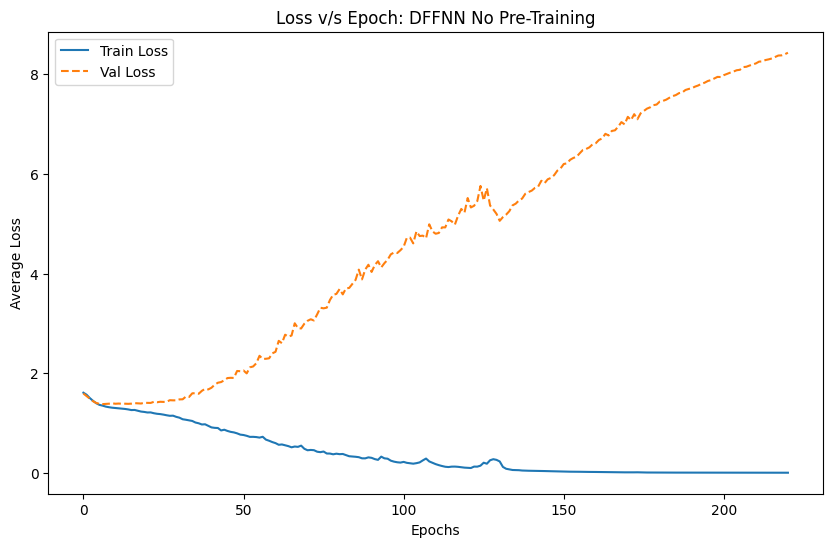

In [46]:
# %%
avg_loss_train_a, avg_loss_val_a = train_DFFNN(DFFNN_A, train_L_loader, val_loader)

# %%
plt.figure(figsize=(10,6))
plt.plot(avg_loss_train_a, label="Train Loss")
plt.plot(avg_loss_val_a, label="Val Loss", linestyle="--")
plt.xlabel("Epochs")
plt.ylabel("Average Loss")
plt.title("Loss v/s Epoch: DFFNN No Pre-Training")
plt.legend()
plt.show()

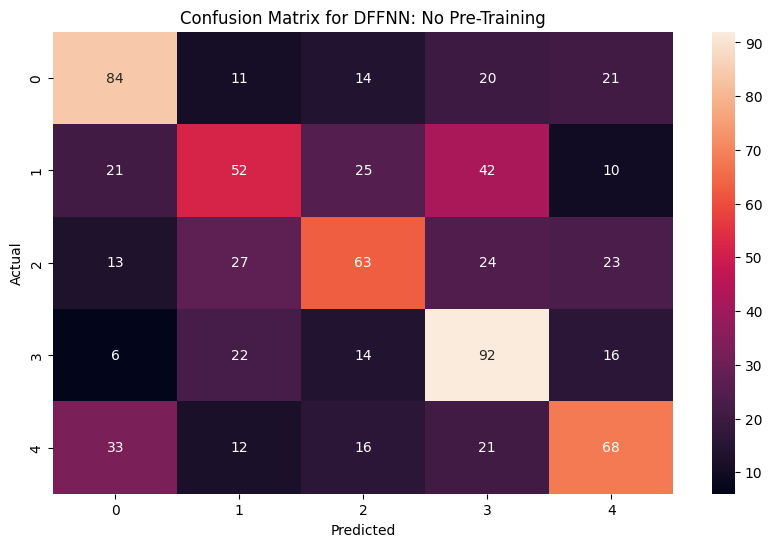

array([[84, 11, 14, 20, 21],
       [21, 52, 25, 42, 10],
       [13, 27, 63, 24, 23],
       [ 6, 22, 14, 92, 16],
       [33, 12, 16, 21, 68]])

In [47]:
evaluate_model(DFFNN_A, train_L_loader, model_type="DFFNN: No Pre-Training")

USING PRETRAINED AUTOENCODER

In [48]:
DFFNN_B = DFFNN(
    input_dim,
    hidden_1,
    bottleneck_1,
    hidden_2,
    bottleneck_2,
    hidden_3,
    bottleneck_3,
    num_classes,
    pretrained=(ae_1,ae_2,ae_3)
)

--------------------- DFFNN model training ---------------------
Epoch: 1 | Train Loss: 1.56826 | Val Loss: 1.49710
Epoch: 51 | Train Loss: 0.58287 | Val Loss: 1.90870
Epoch: 101 | Train Loss: 0.01192 | Val Loss: 5.08544
Epoch: 151 | Train Loss: 0.00222 | Val Loss: 6.50015
Epoch: 201 | Train Loss: 0.00074 | Val Loss: 7.42321
Converged at epoch: 212


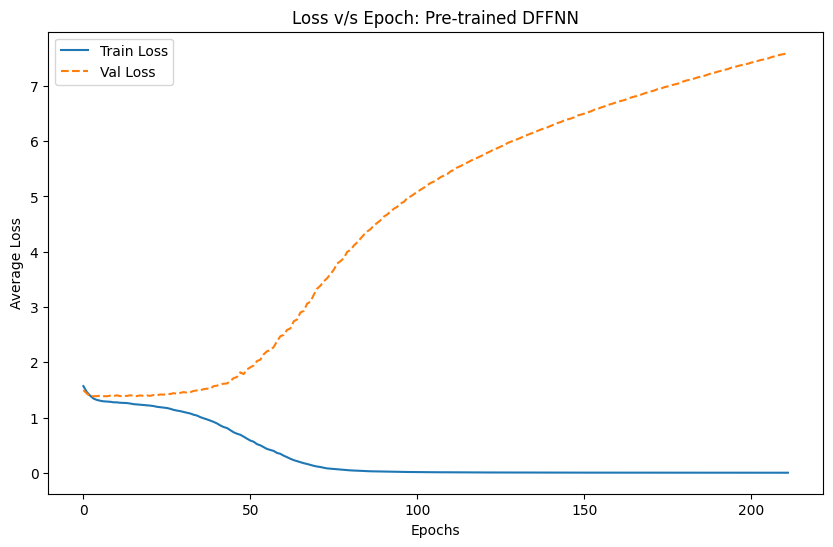

In [49]:
# %%
avg_loss_train_b, avg_loss_val_b = train_DFFNN(DFFNN_B, train_L_loader, val_loader)

# %%
plt.figure(figsize=(10,6))
plt.plot(avg_loss_train_b, label="Train Loss")
plt.plot(avg_loss_val_b, label="Val Loss", linestyle="--")
plt.xlabel("Epochs")
plt.ylabel("Average Loss")
plt.title("Loss v/s Epoch: Pre-trained DFFNN")
plt.legend()
plt.show()

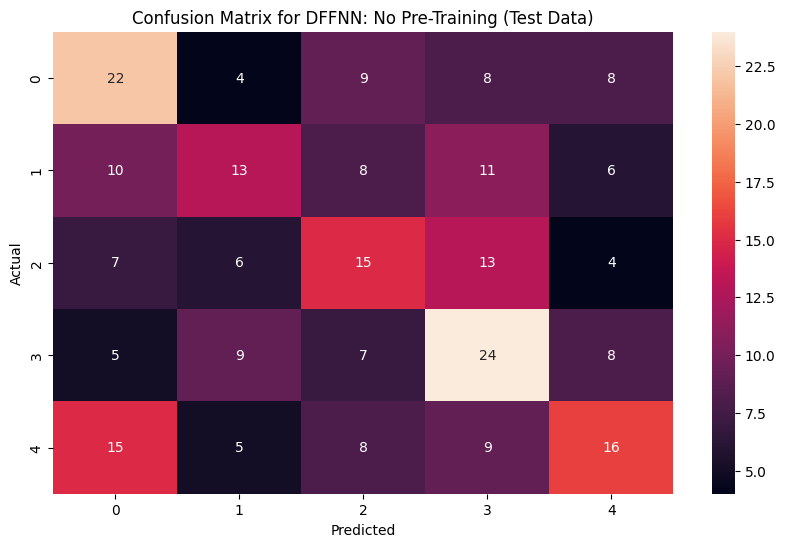

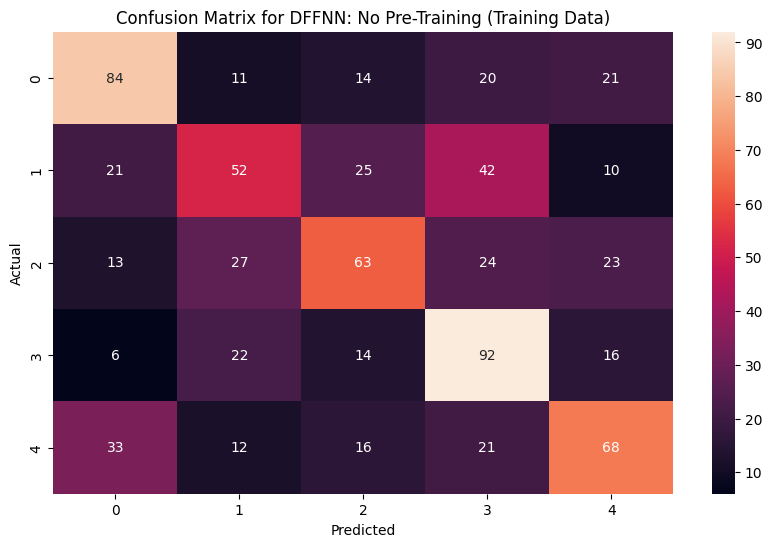

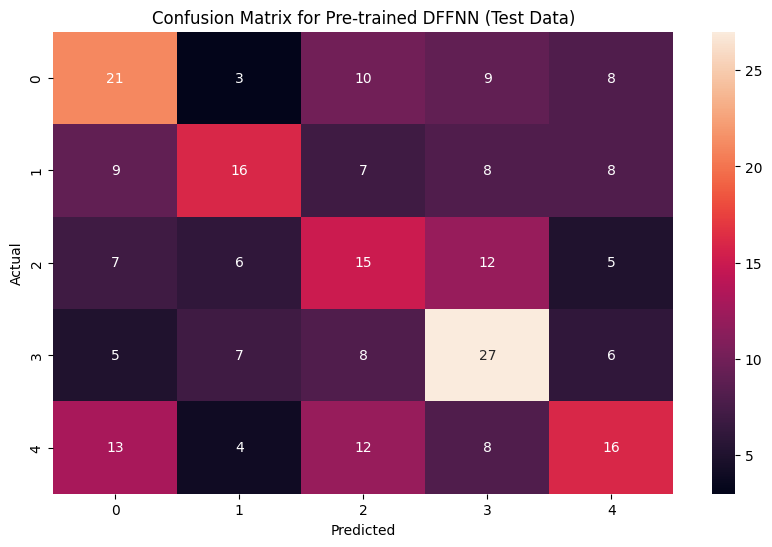

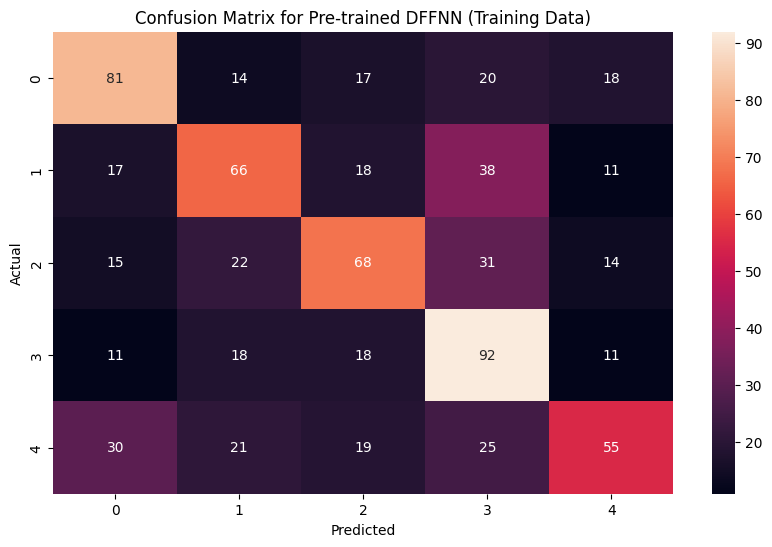

array([[81, 14, 17, 20, 18],
       [17, 66, 18, 38, 11],
       [15, 22, 68, 31, 14],
       [11, 18, 18, 92, 11],
       [30, 21, 19, 25, 55]])

In [50]:
evaluate_model(DFFNN_A, test_loader, model_type="DFFNN: No Pre-Training (Test Data)")
evaluate_model(DFFNN_A, train_L_loader, model_type="DFFNN: No Pre-Training (Training Data)")
evaluate_model(DFFNN_B, test_loader, model_type="Pre-trained DFFNN (Test Data)")
evaluate_model(DFFNN_B, train_L_loader, model_type="Pre-trained DFFNN (Training Data)")